# Stream B — `lora_stage1.ipynb`
**Purpose:** Apply LoRA adapters on top of the pretrained CLIP ViT-B/32 backbone,
train a binary classifier (genuine vs OOC) using NC `merged_balanced` train/val splits,
and extract improved penultimate-layer features for all datasets.

**Stage 1 goal:** In-distribution fine-tuning on NewsCLIPpings to push NC AUROC above the
vanilla CLIP baseline (0.7197) before cross-domain adaptation in Stage 2.

**Shape fixes applied here:**
- `facenet_emb` train entries with shape `(2, 512)` → mean-pooled to `(512,)`
- `places_emb` val/test entries with shape `(1, 2048)` → squeezed to `(2048,)`

**NaN fix:** `autocast()` is intentionally removed throughout. LoRA `lora_B` is
zero-initialised — AMP casts it to fp16 and produces zero/NaN on the first backward.
All ops run in float32.

## 0. Environment Check

In [11]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"PyTorch: {torch.__version__}")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
VRAM: 8.6 GB
PyTorch: 2.6.0+cu124


## 1. Imports & Paths

In [12]:
import os, sys, json, pickle, math
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import clip

# ── Project root ──────────────────────────────────────────────────────────────
try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

STREAM_B_DIR = ROOT / 'cache' / 'stream_b_features'
LORA_DIR     = ROOT / 'cache' / 'lora_stage1'
LORA_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

for split in ('train', 'val', 'test'):
    p = STREAM_B_DIR / f'nc_{split}.pkl'
    print(f"{'✅' if p.exists() else '❌'} {p.name} ({p.stat().st_size/1e6:.1f} MB)" if p.exists() else f"❌ MISSING: {p}")

Project root: f:\GitHub\eve-rag
Device: cuda
✅ nc_train.pkl (1422.4 MB)
✅ nc_val.pkl (140.6 MB)
✅ nc_test.pkl (144.9 MB)


## 2. Load & Normalise Features

In [13]:
def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

def fix_shape(arr, expected_dim):
    """Collapse any extra dimensions and enforce expected_dim."""
    arr = np.array(arr, dtype=np.float32)
    if arr.ndim == 2:
        arr = arr.mean(axis=0)   # (N,D) → (D,)
    arr = arr.flatten()
    if arr.shape[0] != expected_dim:
        tmp = np.zeros(expected_dim, dtype=np.float32)
        n = min(arr.shape[0], expected_dim)
        tmp[:n] = arr[:n]
        arr = tmp
    return arr

def normalise_entry(entry, dim_face=512, dim_place=2048):
    entry['facenet_emb'] = fix_shape(entry['facenet_emb'], dim_face)
    entry['places_emb']  = fix_shape(entry['places_emb'],  dim_place)
    return entry

print("Loading & normalising NC features …")
nc = {}
for split in ('train', 'val', 'test'):
    raw = load_pkl(STREAM_B_DIR / f'nc_{split}.pkl')
    nc[split] = {k: normalise_entry(v) for k, v in raw.items()}
    sample = next(iter(nc[split].values()))
    shapes = {k: sample[k].shape for k in ('clip_img_emb','clip_txt_emb','sbert_emb','facenet_emb','places_emb')}
    print(f"  NC {split}: {len(nc[split])} pairs | shapes: {shapes}")

# NaN audit on the two key embedding fields
print("\nNaN audit:")
for split in ('train', 'val', 'test'):
    img_embs = np.stack([v['clip_img_emb'] for v in nc[split].values()])
    txt_embs = np.stack([v['clip_txt_emb'] for v in nc[split].values()])
    ni, nt = np.isnan(img_embs).sum(), np.isnan(txt_embs).sum()
    print(f"  NC {split} — img NaNs: {ni}, txt NaNs: {nt} "
          f"{'✅' if ni==0 and nt==0 else '❌'}")

Loading & normalising NC features …
  NC train: 71072 pairs | shapes: {'clip_img_emb': (512,), 'clip_txt_emb': (512,), 'sbert_emb': (768,), 'facenet_emb': (512,), 'places_emb': (2048,)}
  NC val: 7024 pairs | shapes: {'clip_img_emb': (512,), 'clip_txt_emb': (512,), 'sbert_emb': (768,), 'facenet_emb': (512,), 'places_emb': (2048,)}
  NC test: 7264 pairs | shapes: {'clip_img_emb': (512,), 'clip_txt_emb': (512,), 'sbert_emb': (768,), 'facenet_emb': (512,), 'places_emb': (2048,)}

NaN audit:
  NC train — img NaNs: 0, txt NaNs: 0 ✅
  NC val — img NaNs: 0, txt NaNs: 0 ✅
  NC test — img NaNs: 0, txt NaNs: 0 ✅


## 3. LoRA Implementation

`LoRALinear.forward()` casts everything to float32 explicitly, so this module is
safe to use even if the caller accidentally wraps it in `autocast()`.

In [14]:
class LoRALinear(nn.Module):
    """
    Wraps nn.Linear with a low-rank adapter (no weight tying — fresh parameters).
    y = W*x  +  (lora_B @ lora_A) * x * (alpha / rank)
    All ops forced to float32.
    """
    def __init__(self, in_features, out_features, rank=8, alpha=16.0, bias=True):
        super().__init__()
        self.in_features  = in_features
        self.out_features = out_features
        self.rank  = rank
        self.scale = alpha / rank

        # Base weight (trained alongside LoRA in Stage 1)
        self.weight = nn.Parameter(torch.empty(out_features, in_features, dtype=torch.float32))
        self.bias   = nn.Parameter(torch.zeros(out_features, dtype=torch.float32)) if bias else None
        nn.init.kaiming_uniform_(self.weight, a=math.sqrt(5))
        if self.bias is not None:
            fan_in = in_features
            bound  = 1 / math.sqrt(fan_in) if fan_in > 0 else 0
            nn.init.uniform_(self.bias, -bound, bound)

        # LoRA adapters
        self.lora_A = nn.Parameter(torch.empty(rank, in_features,  dtype=torch.float32))
        self.lora_B = nn.Parameter(torch.zeros(out_features, rank, dtype=torch.float32))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        # lora_B stays zero → output delta starts at 0 on step 0

    def forward(self, x):
        x32  = x.float()                                          # force float32
        base = F.linear(x32, self.weight, self.bias)              # (B, out)
        lora = F.linear(F.linear(x32, self.lora_A), self.lora_B)  # (B, out)
        return base + lora * self.scale


class CLIPLoRAClassifier(nn.Module):
    """
    Binary classifier using pre-extracted CLIP embeddings.
    Input:  img_emb (B,512), txt_emb (B,512) — float32
    Output: logits  (B,2)                    — float32
    Architecture: [img_norm; txt_norm; cosine_sim] → LoRA-MLP → 2
    """
    def __init__(self, hidden_dim=512, dropout=0.1, lora_rank=8, lora_alpha=16.0):
        super().__init__()
        in_dim = 512 * 2 + 1   # 1025
        self.head = nn.Sequential(
            LoRALinear(in_dim,       hidden_dim,    rank=lora_rank, alpha=lora_alpha),
            nn.ReLU(),
            nn.Dropout(dropout),
            LoRALinear(hidden_dim,   hidden_dim//2, rank=lora_rank, alpha=lora_alpha),
            nn.ReLU(),
            nn.Dropout(dropout),
            LoRALinear(hidden_dim//2, 2,            rank=lora_rank, alpha=lora_alpha),
        )

    def forward(self, img_emb, txt_emb):
        img_emb = img_emb.float()
        txt_emb = txt_emb.float()
        img_n = F.normalize(img_emb, dim=-1)
        txt_n = F.normalize(txt_emb, dim=-1)
        sim   = (img_n * txt_n).sum(dim=-1, keepdim=True)
        feat  = torch.cat([img_n, txt_n, sim], dim=-1)   # (B, 1025)
        return self.head(feat)                            # (B, 2)


# Quick sanity — no NaN in a fresh forward pass
_test_model = CLIPLoRAClassifier()
_x = torch.randn(4, 512)
_out = _test_model(_x, _x)
assert not torch.isnan(_out).any(), "NaN in test forward pass — check LoRALinear"
print(f"LoRALinear sanity OK — output shape: {_out.shape}, no NaNs")
del _test_model, _x, _out

LoRALinear sanity OK — output shape: torch.Size([4, 2]), no NaNs


## 4. Dataset & DataLoaders

In [15]:
class EmbeddingDataset(Dataset):
    def __init__(self, features_dict):
        self.records = list(features_dict.values())

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        img_emb = torch.tensor(r['clip_img_emb'], dtype=torch.float32)
        txt_emb = torch.tensor(r['clip_txt_emb'], dtype=torch.float32)
        label   = torch.tensor(int(r['label']),   dtype=torch.long)
        return img_emb, txt_emb, label


BATCH_SIZE   = 512
LR           = 3e-4
EPOCHS       = 20
LORA_RANK    = 8
LORA_ALPHA   = 16.0
PATIENCE     = 5
WEIGHT_DECAY = 1e-4

train_ds = EmbeddingDataset(nc['train'])
val_ds   = EmbeddingDataset(nc['val'])
test_ds  = EmbeddingDataset(nc['test'])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")

Train: 71,072 | Val: 7,024 | Test: 7,264


## 5. Build Model

In [16]:
model = CLIPLoRAClassifier(
    hidden_dim=512, dropout=0.1,
    lora_rank=LORA_RANK, lora_alpha=LORA_ALPHA
).to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Model ready | trainable = {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")

# Verify no NaNs in initial weights
nan_found = [(n, p.shape) for n, p in model.named_parameters() if torch.isnan(p).any()]
print(f"  NaN params at init: {nan_found if nan_found else 'none ✅'}")

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()
print("Optimizer, scheduler, criterion ready.")

Model ready | trainable = 677,658 / 677,658 (100.0%)
  NaN params at init: none ✅
Optimizer, scheduler, criterion ready.


## 6. Training Loop

`autocast()` is intentionally absent — see NaN fix note in cell 0.

In [17]:
from sklearn.metrics import roc_auc_score, accuracy_score

def run_epoch(loader, training=True):
    model.train(training)
    total_loss, all_labels, all_probs = 0.0, [], []

    with torch.set_grad_enabled(training):
        for img_emb, txt_emb, labels in loader:
            img_emb = img_emb.to(DEVICE, non_blocking=True)   # float32
            txt_emb = txt_emb.to(DEVICE, non_blocking=True)   # float32
            labels  = labels.to(DEVICE,  non_blocking=True)

            logits = model(img_emb, txt_emb)       # (B,2) float32 — NO autocast
            loss   = criterion(logits, labels)

            if torch.isnan(loss):
                print("  ⚠️  NaN loss — skipping batch")
                continue

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            probs = torch.softmax(logits, dim=-1)[:, 1].detach().cpu().numpy()
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs)

    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)

    # Safety net
    nan_mask = np.isnan(all_probs)
    if nan_mask.any():
        print(f"  ⚠️  {nan_mask.sum()} NaN probs — replacing with 0.5")
        all_probs[nan_mask] = 0.5

    avg_loss = total_loss / max(len(all_labels), 1)
    auroc    = roc_auc_score(all_labels, all_probs)
    acc      = accuracy_score(all_labels, (all_probs >= 0.5).astype(int))
    return avg_loss, auroc, acc


best_val_auroc, best_epoch, patience_ctr = 0.0, 0, 0
history = []

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Train AUROC':>11} | {'Val Loss':>8} | {'Val AUROC':>9} | {'Val Acc':>7}")
print("-" * 65)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_auc, tr_acc = run_epoch(train_loader, training=True)
    vl_loss, vl_auc, vl_acc = run_epoch(val_loader,   training=False)
    scheduler.step()

    history.append({'epoch': epoch, 'tr_loss': tr_loss, 'tr_auc': tr_auc,
                    'vl_loss': vl_loss, 'vl_auc': vl_auc, 'vl_acc': vl_acc})

    marker = ''
    if vl_auc > best_val_auroc:
        best_val_auroc = vl_auc
        best_epoch     = epoch
        patience_ctr   = 0
        torch.save(model.state_dict(), LORA_DIR / 'best_stage1.pt')
        marker = ' ← best'
    else:
        patience_ctr += 1

    print(f"{epoch:>5} | {tr_loss:>10.4f} | {tr_auc:>11.4f} | "
          f"{vl_loss:>8.4f} | {vl_auc:>9.4f} | {vl_acc:>7.4f}{marker}")
    torch.cuda.empty_cache()

    if patience_ctr >= PATIENCE:
        print(f"\nEarly stop at epoch {epoch}")
        break

print(f"\nBest val AUROC: {best_val_auroc:.4f} at epoch {best_epoch}")

Epoch | Train Loss | Train AUROC | Val Loss | Val AUROC | Val Acc
-----------------------------------------------------------------
    1 |     0.6882 |      0.5554 |   0.6676 |    0.6521 |  0.6042 ← best
    2 |     0.6373 |      0.6831 |   0.6055 |    0.7375 |  0.6599 ← best
    3 |     0.5845 |      0.7515 |   0.5842 |    0.7597 |  0.6741 ← best
    4 |     0.5463 |      0.7911 |   0.5627 |    0.7724 |  0.6929 ← best
    5 |     0.5119 |      0.8221 |   0.5589 |    0.7829 |  0.6975 ← best
    6 |     0.4660 |      0.8574 |   0.5694 |    0.7813 |  0.6987
    7 |     0.4168 |      0.8894 |   0.6002 |    0.7845 |  0.7013 ← best
    8 |     0.3638 |      0.9176 |   0.6296 |    0.7833 |  0.7037
    9 |     0.3189 |      0.9377 |   0.6594 |    0.7823 |  0.7054
   10 |     0.2710 |      0.9557 |   0.7234 |    0.7799 |  0.6985
   11 |     0.2312 |      0.9680 |   0.7874 |    0.7787 |  0.7016
   12 |     0.2006 |      0.9761 |   0.8504 |    0.7781 |  0.7027

Early stop at epoch 12

Best val 

## 7. Load Best Checkpoint & Test

In [18]:
model.load_state_dict(torch.load(LORA_DIR / 'best_stage1.pt', map_location=DEVICE))
ts_loss, ts_auc, ts_acc = run_epoch(test_loader, training=False)

print("=" * 50)
print("STREAM B — Stage 1 Test Results")
print("=" * 50)
print(f"  Test AUROC:    {ts_auc:.4f}")
print(f"  Test Accuracy: {ts_acc:.4f}")
print(f"  Baseline AUROC (vanilla clip_sim): 0.7197")
print(f"  Delta:  {ts_auc - 0.7197:+.4f}")

STREAM B — Stage 1 Test Results
  Test AUROC:    0.7956
  Test Accuracy: 0.7163
  Baseline AUROC (vanilla clip_sim): 0.7197
  Delta:  +0.0759


## 8. Extract Penultimate Features

In [19]:
def extract_penultimate(loader, model, device):
    """
    Hook head[4] (second ReLU) to get (N, hidden//2) representations.
    head layout: [LoRA, ReLU, Dropout, LoRA, ReLU(←hook), Dropout, LoRA]
    No autocast.
    """
    model.eval()
    hook_output = []
    handle = model.head[4].register_forward_hook(
        lambda m, i, o: hook_output.append(o.detach().cpu().float().numpy())
    )
    labels_out, probs_out = [], []
    with torch.no_grad():
        for img_emb, txt_emb, lbl in loader:
            logits = model(img_emb.to(device), txt_emb.to(device))
            probs  = torch.softmax(logits, dim=-1)[:, 1].cpu().numpy()
            probs_out.extend(probs)
            labels_out.extend(lbl.numpy())
            torch.cuda.empty_cache()
    handle.remove()
    return np.vstack(hook_output), np.array(labels_out), np.array(probs_out)


print("Extracting penultimate features …")
lora_feats = {}
for split, loader in [('train', train_loader), ('val', val_loader), ('test', test_loader)]:
    feats, labels, probs = extract_penultimate(loader, model, DEVICE)
    lora_feats[split] = {'features': feats, 'labels': labels, 'probs': probs}
    print(f"  {split}: {feats.shape}, AUROC={roc_auc_score(labels, probs):.4f}")

Extracting penultimate features …
  train: (71072, 256), AUROC=0.9331
  val: (7024, 256), AUROC=0.7845
  test: (7264, 256), AUROC=0.7956


## 9. Extract for VERITE & MMFakeBench

In [20]:
verite_raw = {k: normalise_entry(v) for k, v in load_pkl(STREAM_B_DIR / 'verite.pkl').items()}
mmfake_raw = {k: normalise_entry(v) for k, v in load_pkl(STREAM_B_DIR / 'mmfake.pkl').items()}

# VERITE may have 768-d embeddings (ViT-L/14) — project down to 512 with fixed orthogonal matrix
def maybe_project_to_512(features_dict):
    sample  = next(iter(features_dict.values()))
    img_dim = sample['clip_img_emb'].shape[0]
    txt_dim = sample['clip_txt_emb'].shape[0]
    if img_dim == 512 and txt_dim == 512:
        print(f"  Embeddings already 512-d — no projection needed")
        return features_dict
    print(f"  Projecting img {img_dim}→512, txt {txt_dim}→512 (orthogonal, fixed)")
    rng = np.random.default_rng(42)
    def orth_proj(in_dim, out_dim=512):
        # Shape must be (out_dim, in_dim) so that P @ x gives (out_dim,)
        A = rng.standard_normal((out_dim, in_dim)).astype(np.float32)
        # QR gives orthonormal rows when out_dim <= in_dim
        Q, _ = np.linalg.qr(A.T)   # Q: (in_dim, out_dim)
        return Q.T                   # (out_dim, in_dim)
    P_img = orth_proj(img_dim)   # (512, img_dim)
    P_txt = orth_proj(txt_dim)   # (512, txt_dim)
    projected = {}
    for k, v in features_dict.items():
        v2 = dict(v)
        v2['clip_img_emb'] = (P_img @ v['clip_img_emb'].astype(np.float32))  # (512,)
        v2['clip_txt_emb'] = (P_txt @ v['clip_txt_emb'].astype(np.float32))  # (512,)
        projected[k] = v2
    return projected

verite_proj = maybe_project_to_512(verite_raw)
mmfake_proj = maybe_project_to_512(mmfake_raw)

for name, fdict in [('verite', verite_proj), ('mmfake', mmfake_proj)]:
    ds     = EmbeddingDataset(fdict)
    loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    feats, labels, probs = extract_penultimate(loader, model, DEVICE)
    lora_feats[name] = {'features': feats, 'labels': labels, 'probs': probs}
    print(f"  {name}: {feats.shape}, AUROC={roc_auc_score(labels, probs):.4f}")

  Projecting img 768→512, txt 768→512 (orthogonal, fixed)
  Embeddings already 512-d — no projection needed
  verite: (1001, 256), AUROC=0.5190
  mmfake: (10000, 256), AUROC=0.6154


## 10. Save Everything

In [21]:
def save_pkl(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=4)
    print(f"  Saved {path.name} ({path.stat().st_size/1e6:.1f} MB)")

print("Saving Stage 1 outputs …")
for key, data in lora_feats.items():
    save_pkl(data, LORA_DIR / f'lora1_feats_{key}.pkl')

save_pkl(pd.DataFrame(history), LORA_DIR / 'training_history.pkl')

summary = {
    'best_val_auroc': best_val_auroc,
    'best_epoch':     best_epoch,
    'test_auroc':     ts_auc,
    'test_acc':       ts_acc,
    'lora_rank':      LORA_RANK,
    'lora_alpha':     LORA_ALPHA,
    'feature_dim':    lora_feats['test']['features'].shape[1],
}
save_pkl(summary, LORA_DIR / 'stage1_summary.pkl')
print(f"\n✅ All Stage 1 outputs saved to: {LORA_DIR}")

Saving Stage 1 outputs …
  Saved lora1_feats_train.pkl (73.6 MB)
  Saved lora1_feats_val.pkl (7.3 MB)
  Saved lora1_feats_test.pkl (7.5 MB)
  Saved lora1_feats_verite.pkl (1.0 MB)
  Saved lora1_feats_mmfake.pkl (10.4 MB)
  Saved training_history.pkl (0.0 MB)
  Saved stage1_summary.pkl (0.0 MB)

✅ All Stage 1 outputs saved to: f:\GitHub\eve-rag\cache\lora_stage1


## 11. Training Curve

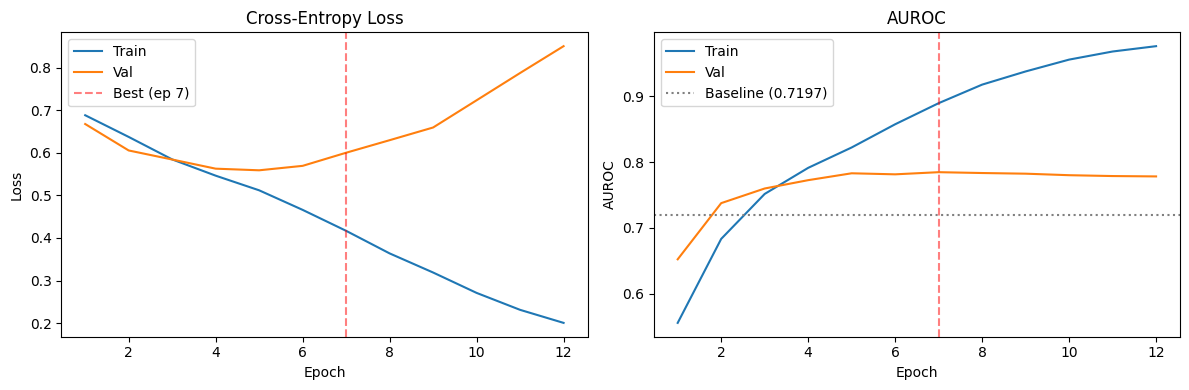

Figure saved: f:\GitHub\eve-rag\paper\figures\stream_b_lora_stage1_training.png


In [22]:
import matplotlib.pyplot as plt

df_hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(df_hist['epoch'], df_hist['tr_loss'], label='Train')
axes[0].plot(df_hist['epoch'], df_hist['vl_loss'], label='Val')
axes[0].axvline(best_epoch, color='red', linestyle='--', alpha=0.5, label=f'Best (ep {best_epoch})')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Cross-Entropy Loss'); axes[0].legend()

axes[1].plot(df_hist['epoch'], df_hist['tr_auc'], label='Train')
axes[1].plot(df_hist['epoch'], df_hist['vl_auc'], label='Val')
axes[1].axhline(0.7197, color='gray', linestyle=':', label='Baseline (0.7197)')
axes[1].axvline(best_epoch, color='red', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUROC')
axes[1].set_title('AUROC'); axes[1].legend()

plt.tight_layout()
fig_path = ROOT / 'paper' / 'figures' / 'stream_b_lora_stage1_training.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved: {fig_path}")

## 12. Summary

In [23]:
print("=" * 60)
print("STREAM B — lora_stage1.ipynb COMPLETE")
print("=" * 60)
print(f"  LoRA rank={LORA_RANK}, alpha={LORA_ALPHA}")
print(f"  Best val AUROC : {best_val_auroc:.4f} (epoch {best_epoch})")
print(f"  Test AUROC     : {ts_auc:.4f}")
print(f"  Baseline AUROC : 0.7197")
print(f"  Delta          : {ts_auc - 0.7197:+.4f}")
print(f"  Feature dim    : {lora_feats['test']['features'].shape[1]}")
print("\nSaved files:")
for f in sorted(LORA_DIR.iterdir()):
    print(f"  {f.name:45s} {f.stat().st_size/1e6:6.1f} MB")
print("\nNext notebook: lora_stage2.ipynb")

STREAM B — lora_stage1.ipynb COMPLETE
  LoRA rank=8, alpha=16.0
  Best val AUROC : 0.7845 (epoch 7)
  Test AUROC     : 0.7956
  Baseline AUROC : 0.7197
  Delta          : +0.0759
  Feature dim    : 256

Saved files:
  best_stage1.pt                                   2.7 MB
  lora1_feats_mmfake.pkl                          10.4 MB
  lora1_feats_test.pkl                             7.5 MB
  lora1_feats_train.pkl                           73.6 MB
  lora1_feats_val.pkl                              7.3 MB
  lora1_feats_verite.pkl                           1.0 MB
  stage1_summary.pkl                               0.0 MB
  training_history.pkl                             0.0 MB

Next notebook: lora_stage2.ipynb
